# Life Expectancy (WHO) — Data Analysis I Final Project
Runs the full pipeline: **inspection → missing values → invalid values → outliers → feature engineering → EDA → modeling → evaluation**.

**How to use**
1. Run all cells top to bottom (*Runtime → Run all*); the dataset is downloaded automatically via `kagglehub`.
2. Figures are saved in `figs/` and summary tables in `results/`.

## 0. Setup

In [62]:
import kagglehub
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

os.makedirs("figs", exist_ok=True)
os.makedirs("results", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"figs/{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

## 1. Load data

In [63]:
path = kagglehub.dataset_download("kumarajarshi/life-expectancy-who")
data = pd.read_csv(path + "/Life Expectancy Data.csv")
raw_shape = data.shape
print("Raw shape:", raw_shape)
data.head()

Raw shape: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## 2. Initial inspection

In [64]:
print("Original column names:", list(data.columns), "\n")

# strip spaces, lowercase, replace spaces / hyphens / slashes with underscores
data.columns = (data.columns.str.strip().str.lower()
                .str.replace(r"[\s\-/]+", "_", regex=True))
print("Cleaned column names:", list(data.columns))

Original column names: ['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years', ' thinness 5-9 years', 'Income composition of resources', 'Schooling'] 

Cleaned column names: ['country', 'year', 'status', 'life_expectancy', 'adult_mortality', 'infant_deaths', 'alcohol', 'percentage_expenditure', 'hepatitis_b', 'measles', 'bmi', 'under_five_deaths', 'polio', 'total_expenditure', 'diphtheria', 'hiv_aids', 'gdp', 'population', 'thinness_1_19_years', 'thinness_5_9_years', 'income_composition_of_resources', 'schooling']


In [65]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   country                          2938 non-null   str    
 1   year                             2938 non-null   int64  
 2   status                           2938 non-null   str    
 3   life_expectancy                  2928 non-null   float64
 4   adult_mortality                  2928 non-null   float64
 5   infant_deaths                    2938 non-null   int64  
 6   alcohol                          2744 non-null   float64
 7   percentage_expenditure           2938 non-null   float64
 8   hepatitis_b                      2385 non-null   float64
 9   measles                          2938 non-null   int64  
 10  bmi                              2904 non-null   float64
 11  under_five_deaths                2938 non-null   int64  
 12  polio                          

In [66]:
summary = data.describe().T
summary["median"] = data.median(numeric_only=True)
summary.to_csv("results/summary_statistics_raw.csv")
display(summary)

print("Countries:", data["country"].nunique(),
      "| Years:", data["year"].min(), "-", data["year"].max())
print("\nStatus counts:\n", data["status"].value_counts())
print("\nDuplicate rows:", data.duplicated().sum())
print("Duplicate (country, year) pairs:", data.duplicated(subset=["country", "year"]).sum())
print("Numeric columns:", data.select_dtypes("number").shape[1],
      "| Categorical columns:", data.select_dtypes("object").shape[1])

,count,mean,std,min,25%,50%,75%,max,median
year,2938.0,2.007519e+03,4.613841e+00,2000.00000,2004.000000,2.008000e+03,2.012000e+03,2.015000e+03,2.008000e+03
life_expectancy,2928.0,6.922493e+01,9.523867e+00,36.30000,63.100000,7.210000e+01,7.570000e+01,8.900000e+01,7.210000e+01
adult_mortality,2928.0,1.647964e+02,1.242921e+02,1.00000,74.000000,1.440000e+02,2.280000e+02,7.230000e+02,1.440000e+02
infant_deaths,2938.0,3.030395e+01,1.179265e+02,0.00000,0.000000,3.000000e+00,2.200000e+01,1.800000e+03,3.000000e+00
alcohol,2744.0,4.602861e+00,4.052413e+00,0.01000,0.877500,3.755000e+00,7.702500e+00,1.787000e+01,3.755000e+00
percentage_expenditure,2938.0,7.382513e+02,1.987915e+03,0.00000,4.685343,6.491291e+01,4.415341e+02,1.947991e+04,6.491291e+01
hepatitis_b,2385.0,8.094046e+01,2.507002e+01,1.00000,77.000000,9.200000e+01,9.700000e+01,9.900000e+01,9.200000e+01
measles,2938.0,2.419592e+03,1.146727e+04,0.00000,0.000000,1.700000e+01,3.602500e+02,2.121830e+05,1.700000e+01
bmi,2904.0,3.832125e+01,2.004403e+01,1.00000,19.300000,4.350000e+01,5.620000e+01,8.730000e+01,4.350000e+01
under_five_deaths,2938.0,4.203574e+01,1.604455e+02,0.00000,0.000000,4.000000e+00,2.800000e+01,2.500000e+03,4.000000e+00


Countries: 193 | Years: 2000 - 2015

Status counts:
 status
Developing    2426
Developed      512
Name: count, dtype: int64

Duplicate rows: 0
Duplicate (country, year) pairs: 0
Numeric columns: 20 | Categorical columns: 2


## 3. Missing values

,missing_n,missing_pct
population,652,22.19
hepatitis_b,553,18.82
gdp,448,15.25
total_expenditure,226,7.69
alcohol,194,6.60
income_composition_of_resources,167,5.68
schooling,163,5.55
thinness_5_9_years,34,1.16
thinness_1_19_years,34,1.16
bmi,34,1.16


Columns with missing values: 14


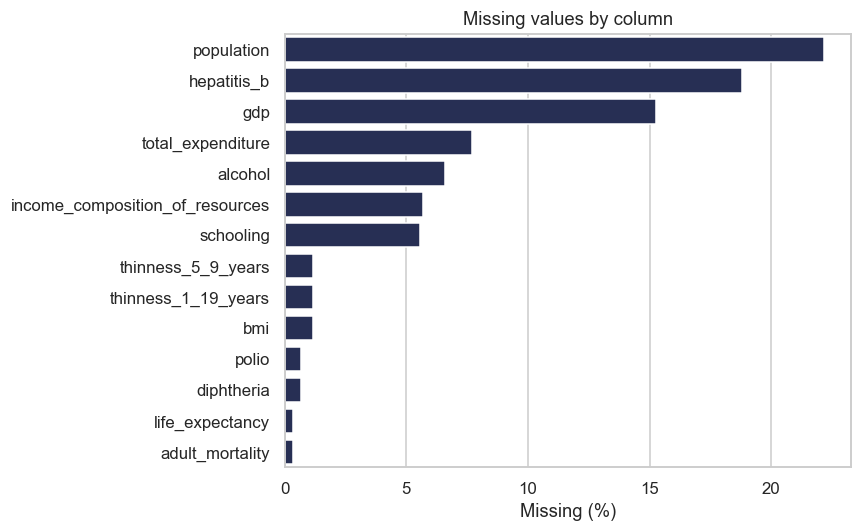

In [67]:
miss = data.isnull().sum()
miss_table = (pd.DataFrame({"missing_n": miss, "missing_pct": (miss / len(data) * 100).round(2)})
              .query("missing_n > 0").sort_values("missing_n", ascending=False))
miss_table.to_csv("results/missing_values.csv")
display(miss_table)
print("Columns with missing values:", len(miss_table))

plt.figure(figsize=(8, 5))
sns.barplot(x=miss_table["missing_pct"], y=miss_table.index, color="#1F2A5C")
plt.xlabel("Missing (%)"); plt.ylabel(""); plt.title("Missing values by column")
save("missing_values_bar")

In [68]:
# Is missingness random? Check where the biggest gaps sit.
for col in ["population", "gdp", "hepatitis_b"]:
    by_country = data.groupby("country")[col].apply(lambda s: s.isna().sum())
    all_missing = data.groupby("country")[col].apply(lambda s: s.isna().all()).sum()
    print(f"--- {col} ---")
    print("Missing rate by status (%):",
          data.groupby("status")[col].apply(lambda s: round(s.isna().mean() * 100, 1)).to_dict())
    print("Countries with any missing:", int((by_country > 0).sum()),
          "| countries missing in ALL years:", int(all_missing))
    print("Top 5 countries by missing count:", by_country.sort_values(ascending=False).head(5).to_dict())
    print("Missing by year:", data.groupby("year")[col].apply(lambda s: int(s.isna().sum())).to_dict(), "\n")

print("Rows with missing life_expectancy are the same as missing adult_mortality:",
      (data["life_expectancy"].isna() == data["adult_mortality"].isna()).all())

--- population ---
Missing rate by status (%): {'Developed': 18.8, 'Developing': 22.9}
Countries with any missing: 49 | countries missing in ALL years: 48
Top 5 countries by missing count: {'Antigua and Barbuda': 16, 'Egypt': 16, 'Barbados': 16, 'Bahrain': 16, 'Bahamas': 16}
Missing by year: {2000: 40, 2001: 40, 2002: 40, 2003: 40, 2004: 40, 2005: 40, 2006: 40, 2007: 40, 2008: 40, 2009: 40, 2010: 40, 2011: 40, 2012: 41, 2013: 49, 2014: 41, 2015: 41} 

--- gdp ---
Missing rate by status (%): {'Developed': 12.5, 'Developing': 15.8}
Countries with any missing: 38 | countries missing in ALL years: 30
Top 5 countries by missing count: {'Bahamas': 16, 'Gambia': 16, 'Bolivia (Plurinational State of)': 16, 'Egypt': 16, "Democratic People's Republic of Korea": 16}
Missing by year: {2000: 29, 2001: 28, 2002: 28, 2003: 28, 2004: 27, 2005: 27, 2006: 27, 2007: 27, 2008: 27, 2009: 27, 2010: 27, 2011: 27, 2012: 29, 2013: 33, 2014: 28, 2015: 29} 

--- hepatitis_b ---
Missing rate by status (%): {'Deve

In [69]:
# The target must not be imputed -> drop rows where it is missing
before = len(data)
data = data.dropna(subset=["life_expectancy"]).reset_index(drop=True)
print(f"Dropped {before - len(data)} rows with missing life_expectancy. Rows now: {len(data)}")

Dropped 10 rows with missing life_expectancy. Rows now: 2928


## 4. Invalid values

In [70]:
pop_big = data["population"] > 1_000_000

rules = {
    # --- will be set to NaN and imputed ---
    "bmi outside 10-60": (data["bmi"] < 10) | (data["bmi"] > 60),
    "schooling == 0": data["schooling"] == 0,
    "income_composition_of_resources == 0": data["income_composition_of_resources"] == 0,
    "population < 1000": data["population"] < 1000,
    "infant_deaths == 0 with population > 1M": (data["infant_deaths"] == 0) & pop_big,
    "under_five_deaths == 0 with population > 1M": (data["under_five_deaths"] == 0) & pop_big,
    # --- flagged only (handled by log transform, not removed) ---
    "under_five_deaths < infant_deaths": data["under_five_deaths"] < data["infant_deaths"],
    "measles > 1000 (reported per 1000 pop.)": data["measles"] > 1000,
    "percentage_expenditure > 100 (%)": data["percentage_expenditure"] > 100,
    "adult_mortality < 10": data["adult_mortality"] < 10,
    "immunization coverage > 100": ((data[["hepatitis_b", "polio", "diphtheria"]] > 100).any(axis=1)),
}
invalid_table = pd.DataFrame({"rule": list(rules), "rows_flagged": [int(m.sum()) for m in rules.values()]})
invalid_table["action"] = ["set to NaN, impute"] * 6 + ["flag only", "flag only, log-transform", "flag only, log-transform", "flag only", "none"]
invalid_table.to_csv("results/invalid_values.csv", index=False)
display(invalid_table)

,rule,rows_flagged,action
0,bmi outside 10-60,629,"set to NaN, impute"
1,schooling == 0,26,"set to NaN, impute"
2,income_composition_of_resources == 0,130,"set to NaN, impute"
3,population < 1000,30,"set to NaN, impute"
4,infant_deaths == 0 with population > 1M,174,"set to NaN, impute"
5,under_five_deaths == 0 with population > 1M,151,"set to NaN, impute"
6,under_five_deaths < infant_deaths,0,flag only
7,measles > 1000 (reported per 1000 pop.),525,"flag only, log-transform"
8,percentage_expenditure > 100 (%),1301,"flag only, log-transform"
9,adult_mortality < 10,86,flag only


In [71]:
# Apply: set clearly impossible values to NaN (they are imputed in the next step)
data.loc[rules["bmi outside 10-60"], "bmi"] = np.nan
data.loc[rules["schooling == 0"], "schooling"] = np.nan
data.loc[rules["income_composition_of_resources == 0"], "income_composition_of_resources"] = np.nan
data.loc[rules["population < 1000"], "population"] = np.nan
data.loc[rules["infant_deaths == 0 with population > 1M"], "infant_deaths"] = np.nan
data.loc[rules["under_five_deaths == 0 with population > 1M"], "under_five_deaths"] = np.nan

print("Missing values after invalid -> NaN:", int(data.isnull().sum().sum()))

Missing values after invalid -> NaN: 3653


## 5. Imputation (country median → status median)

In [72]:
num_cols = data.select_dtypes("number").columns.drop(["life_expectancy", "year"]).tolist()

for col in num_cols:
    data[col] = data.groupby("country")[col].transform(lambda s: s.fillna(s.median()))
    data[col] = data.groupby("status")[col].transform(lambda s: s.fillna(s.median()))

print("Remaining missing values:", int(data.isnull().sum().sum()))
print("Shape after cleaning:", data.shape)

Remaining missing values: 0
Shape after cleaning: (2928, 22)


## 6. Outliers (IQR) and skewness

In [73]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

rows = []
for col in num_cols + ["life_expectancy"]:
    lo, hi = iqr_bounds(data[col])
    n = int(((data[col] < lo) | (data[col] > hi)).sum())
    rows.append({"feature": col, "lower": round(lo, 2), "upper": round(hi, 2),
                 "outliers_n": n, "outliers_pct": round(n / len(data) * 100, 2),
                 "skewness": round(data[col].skew(), 2)})
outlier_table = pd.DataFrame(rows).sort_values("outliers_n", ascending=False)
outlier_table.to_csv("results/outliers_iqr.csv", index=False)
display(outlier_table)

,feature,lower,upper,outliers_n,outliers_pct,skewness
5,measles,-543.38,905.62,542,18.51,9.43
11,hiv_aids,-0.95,1.85,542,18.51,5.39
12,gdp,-6777.48,12791.74,459,15.68,3.46
13,population,-5829613.25,10846210.75,452,15.44,17.94
7,under_five_deaths,-42.00,70.00,394,13.46,9.48
3,percentage_expenditure,-651.79,1099.25,388,13.25,4.64
1,infant_deaths,-33.00,55.00,315,10.76,9.77
10,diphtheria,49.50,125.50,308,10.52,-2.05
4,hepatitis_b,43.50,127.50,293,10.01,-1.83
8,polio,48.88,125.88,278,9.49,-2.07


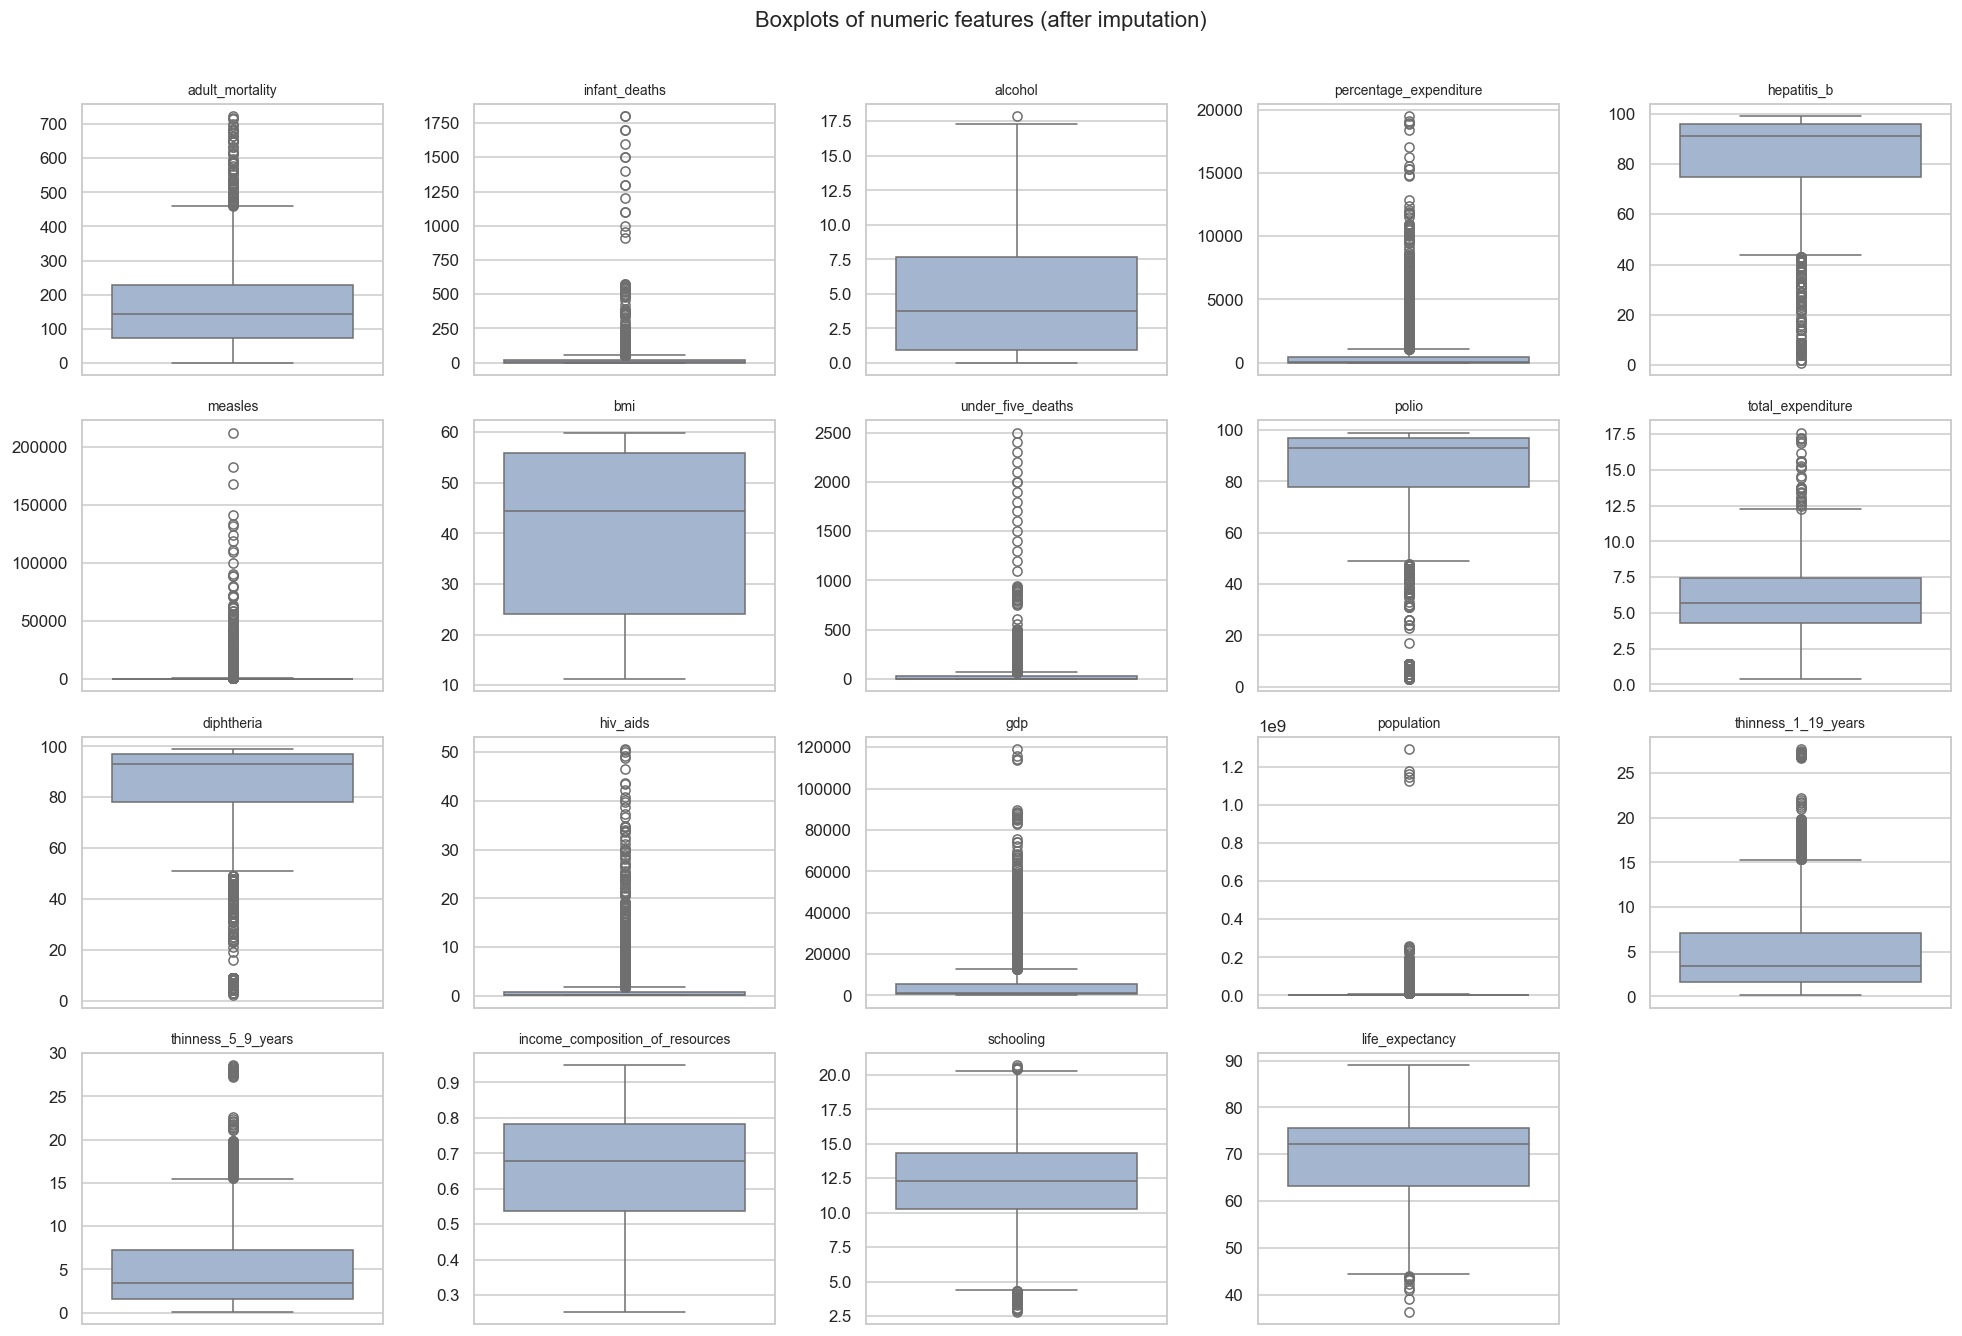

In [74]:
cols = num_cols + ["life_expectancy"]
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(y=data[col], ax=ax, color="#9DB4D6"); ax.set_title(col, fontsize=9); ax.set_ylabel("")
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")
plt.suptitle("Boxplots of numeric features (after imputation)", y=1.01)
save("boxplots_numeric")

In [75]:
# Decision: outliers are genuine (e.g. large countries, epidemics) -> KEEP them,
# and reduce skewness with log1p on highly skewed features (done in the modeling section).
skew_cols = [c for c in num_cols if data[c].skew() > 1.5]
print("Highly skewed features (skew > 1.5):", skew_cols)

skew_after = pd.DataFrame({"before": data[skew_cols].skew(), "after_log1p": np.log1p(data[skew_cols]).skew()}).round(2)
skew_after.to_csv("results/skewness_before_after.csv")
display(skew_after)

Highly skewed features (skew > 1.5): ['infant_deaths', 'percentage_expenditure', 'measles', 'under_five_deaths', 'hiv_aids', 'gdp', 'population', 'thinness_1_19_years', 'thinness_5_9_years']


,before,after_log1p
infant_deaths,9.77,0.70
percentage_expenditure,4.64,-0.08
measles,9.43,0.55
under_five_deaths,9.48,0.65
hiv_aids,5.39,2.12
gdp,3.46,-0.10
population,17.94,-0.37
thinness_1_19_years,1.72,0.13
thinness_5_9_years,1.79,0.10


## 7. Feature engineering

In [76]:
data["period"] = pd.cut(data["year"], bins=[1999, 2004, 2009, 2015], labels=["2000-04", "2005-09", "2010-15"])
data["income_tier"] = pd.qcut(data["gdp"], 3, labels=["Low", "Medium", "High"])

print(data[["period", "income_tier"]].describe(include="all"))
print("\nFinal cleaned shape:", data.shape)
data.to_csv("results/cleaned_data.csv", index=False)

         period income_tier
count      2928        2928
unique        3           3
top     2010-15         Low
freq       1098         976

Final cleaned shape: (2928, 24)


## 8. Exploratory data analysis

### 8.1 Univariate

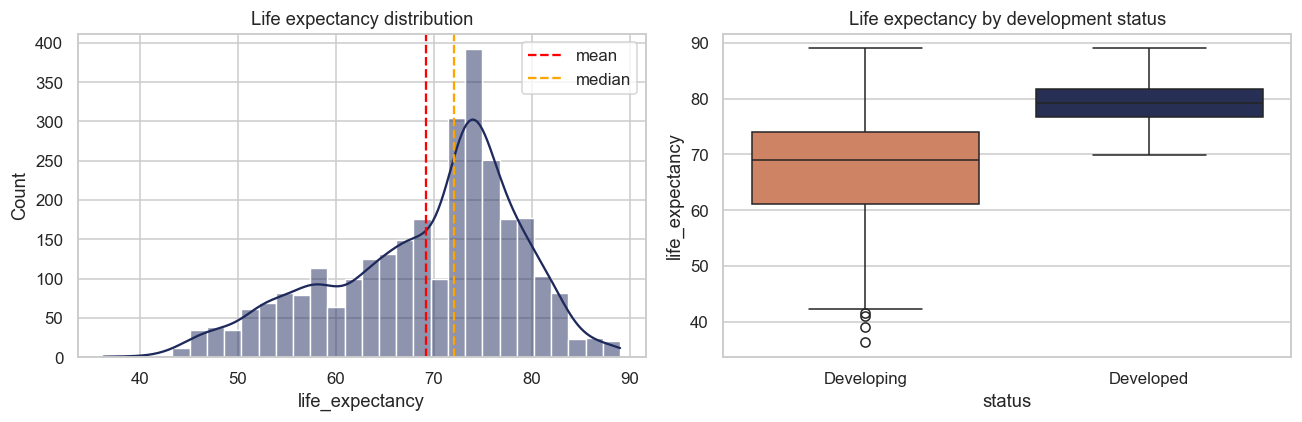

Target skewness: -0.639
            count   mean  median   std
status                                
Developed     512  79.20   79.25  3.93
Developing   2416  67.11   69.00  9.01


In [77]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data["life_expectancy"], kde=True, bins=30, color="#1F2A5C", ax=axes[0])
axes[0].axvline(data["life_expectancy"].mean(), color="red", ls="--", label="mean")
axes[0].axvline(data["life_expectancy"].median(), color="orange", ls="--", label="median")
axes[0].legend(); axes[0].set_title("Life expectancy distribution")
sns.boxplot(data=data, x="status", y="life_expectancy", palette=["#E07B54", "#1F2A5C"], ax=axes[1])
axes[1].set_title("Life expectancy by development status")
save("target_distribution")

print("Target skewness:", round(data["life_expectancy"].skew(), 3))
print(data.groupby("status")["life_expectancy"].agg(["count", "mean", "median", "std"]).round(2))

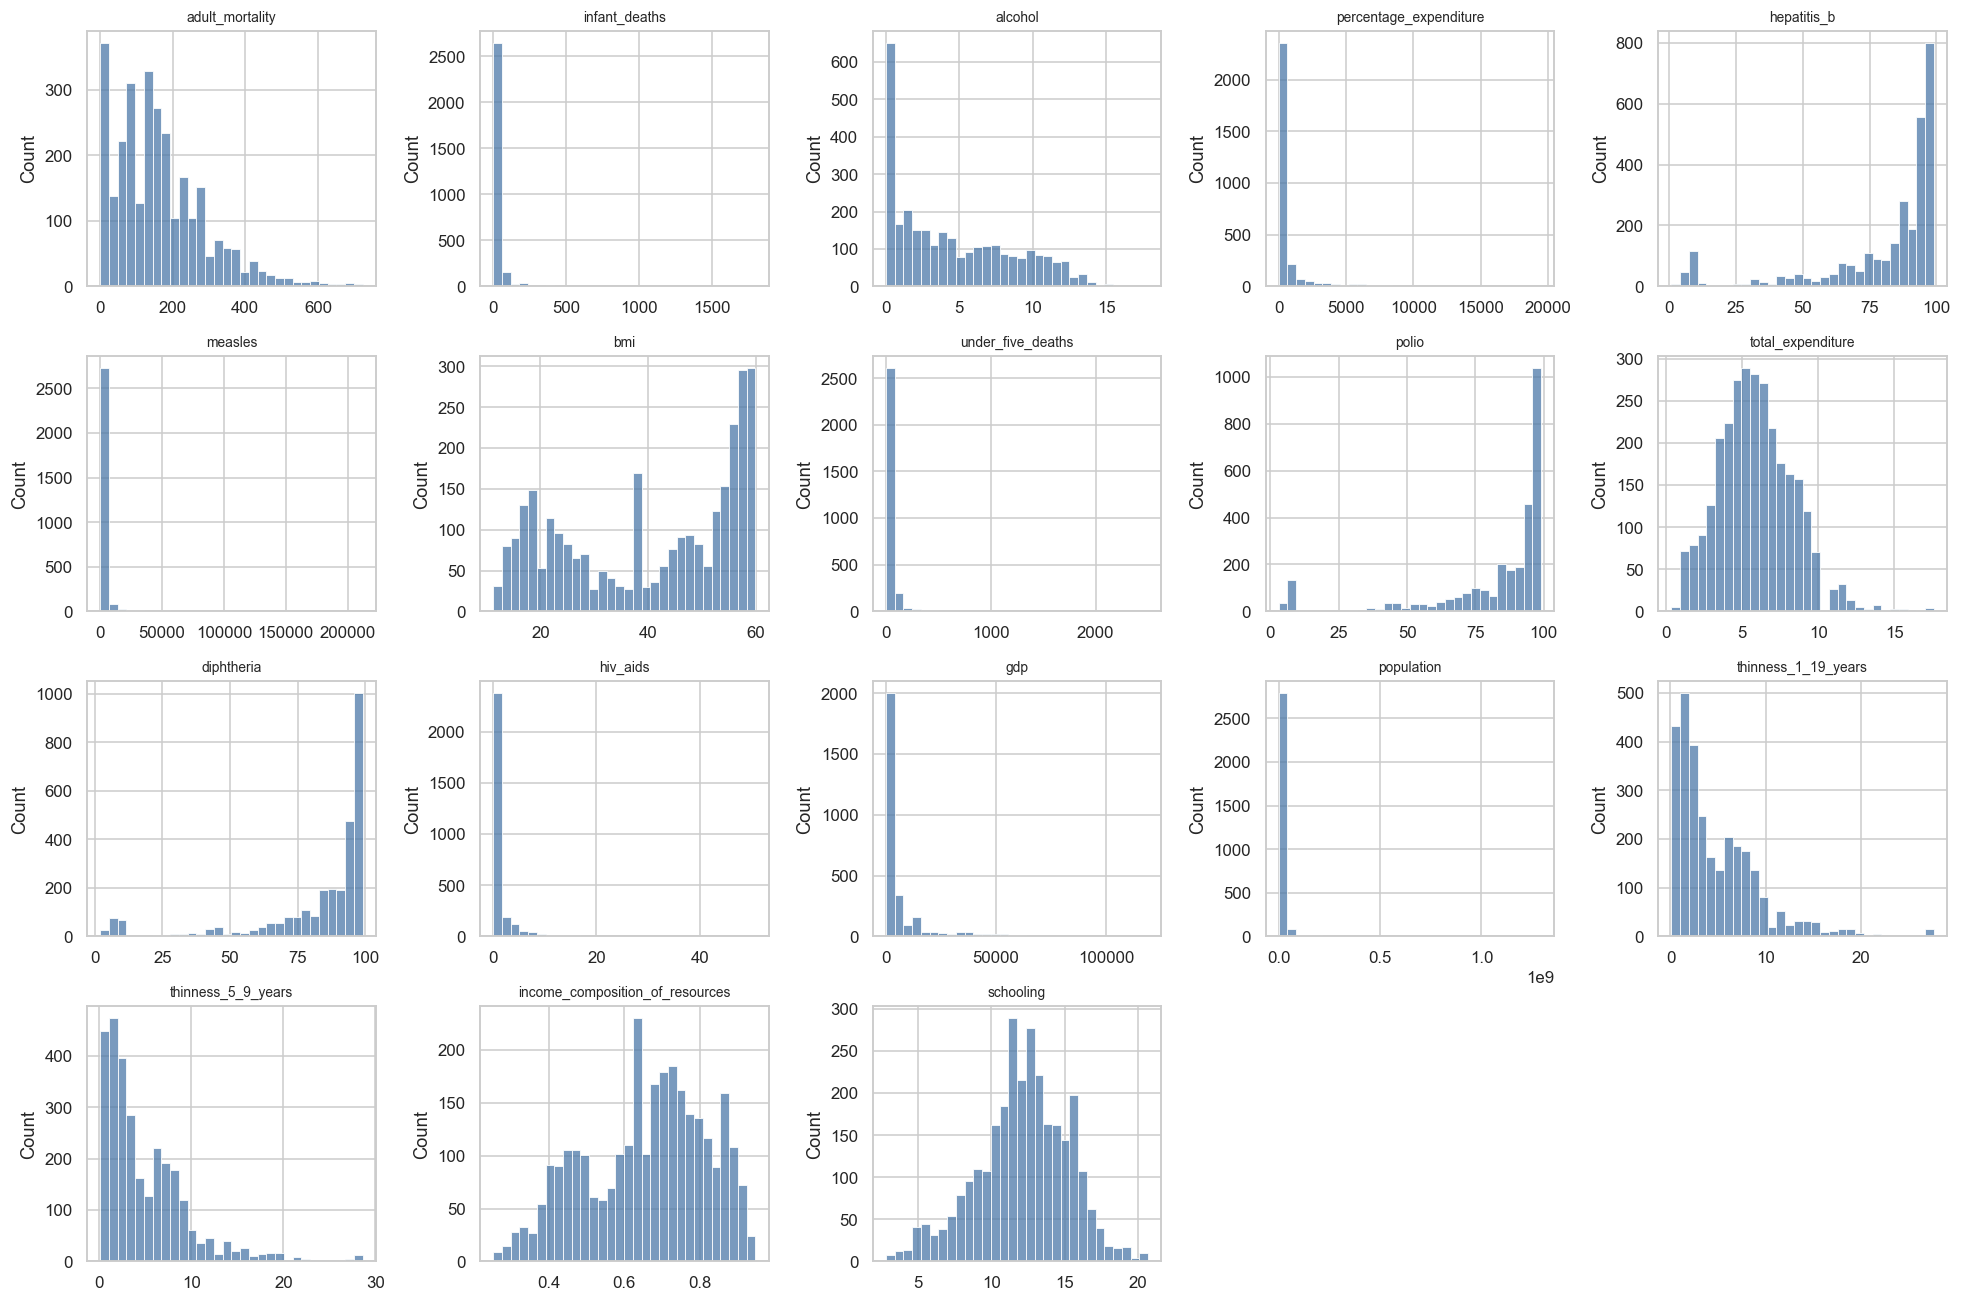

In [78]:
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data[col], bins=30, color="#4C78A8", ax=ax); ax.set_title(col, fontsize=9); ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
save("histograms_numeric")

### 8.2 Bivariate

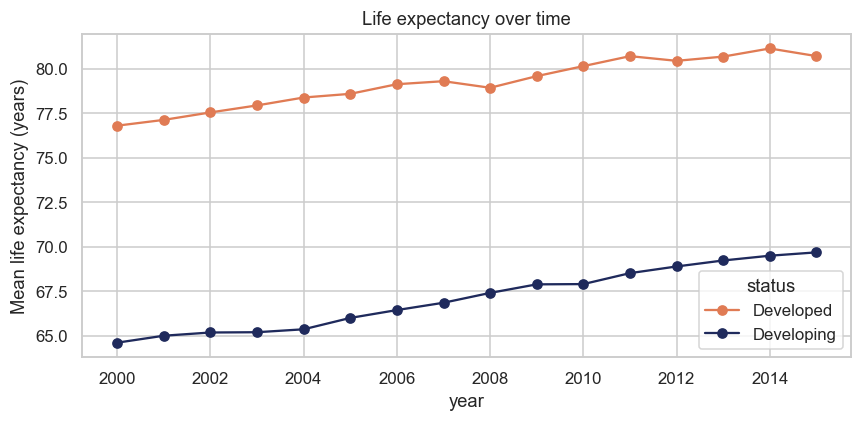

status,Developed,Developing
year,,
2000,76.80,64.62
2015,80.71,69.69


In [79]:
trend = data.groupby(["year", "status"])["life_expectancy"].mean().unstack()
trend.plot(marker="o", figsize=(8, 4), color=["#E07B54", "#1F2A5C"])
plt.ylabel("Mean life expectancy (years)"); plt.title("Life expectancy over time")
save("trend_by_year")
display(trend.round(2).iloc[[0, -1]])

,pearson,spearman
income_composition_of_resources,0.861,0.883
schooling,0.765,0.809
bmi,0.727,0.740
adult_mortality,-0.696,-0.650
hiv_aids,-0.557,-0.754
diphtheria,0.485,0.549
thinness_1_19_years,-0.472,-0.609
polio,0.472,0.539
thinness_5_9_years,-0.466,-0.619
gdp,0.448,0.630


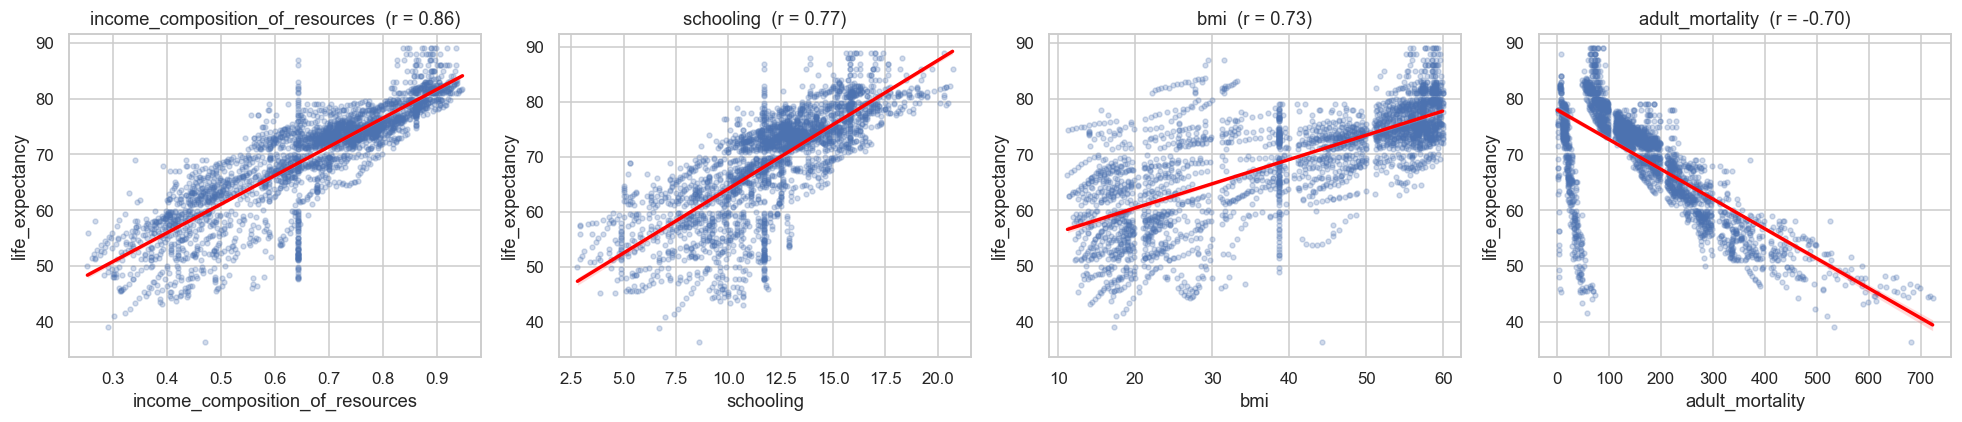

In [80]:
corr_pearson = data[num_cols + ["life_expectancy"]].corr(method="pearson")
corr_spearman = data[num_cols + ["life_expectancy"]].corr(method="spearman")

target_corr = pd.DataFrame({"pearson": corr_pearson["life_expectancy"],
                            "spearman": corr_spearman["life_expectancy"]}).drop("life_expectancy")
target_corr = target_corr.reindex(target_corr["pearson"].abs().sort_values(ascending=False).index).round(3)
target_corr.to_csv("results/correlation_with_target.csv")
display(target_corr)

top4 = target_corr.index[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, top4):
    sns.regplot(data=data, x=col, y="life_expectancy", ax=ax,
                scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "red"})
    ax.set_title(f"{col}  (r = {target_corr.loc[col, 'pearson']:.2f})")
save("scatter_top4")

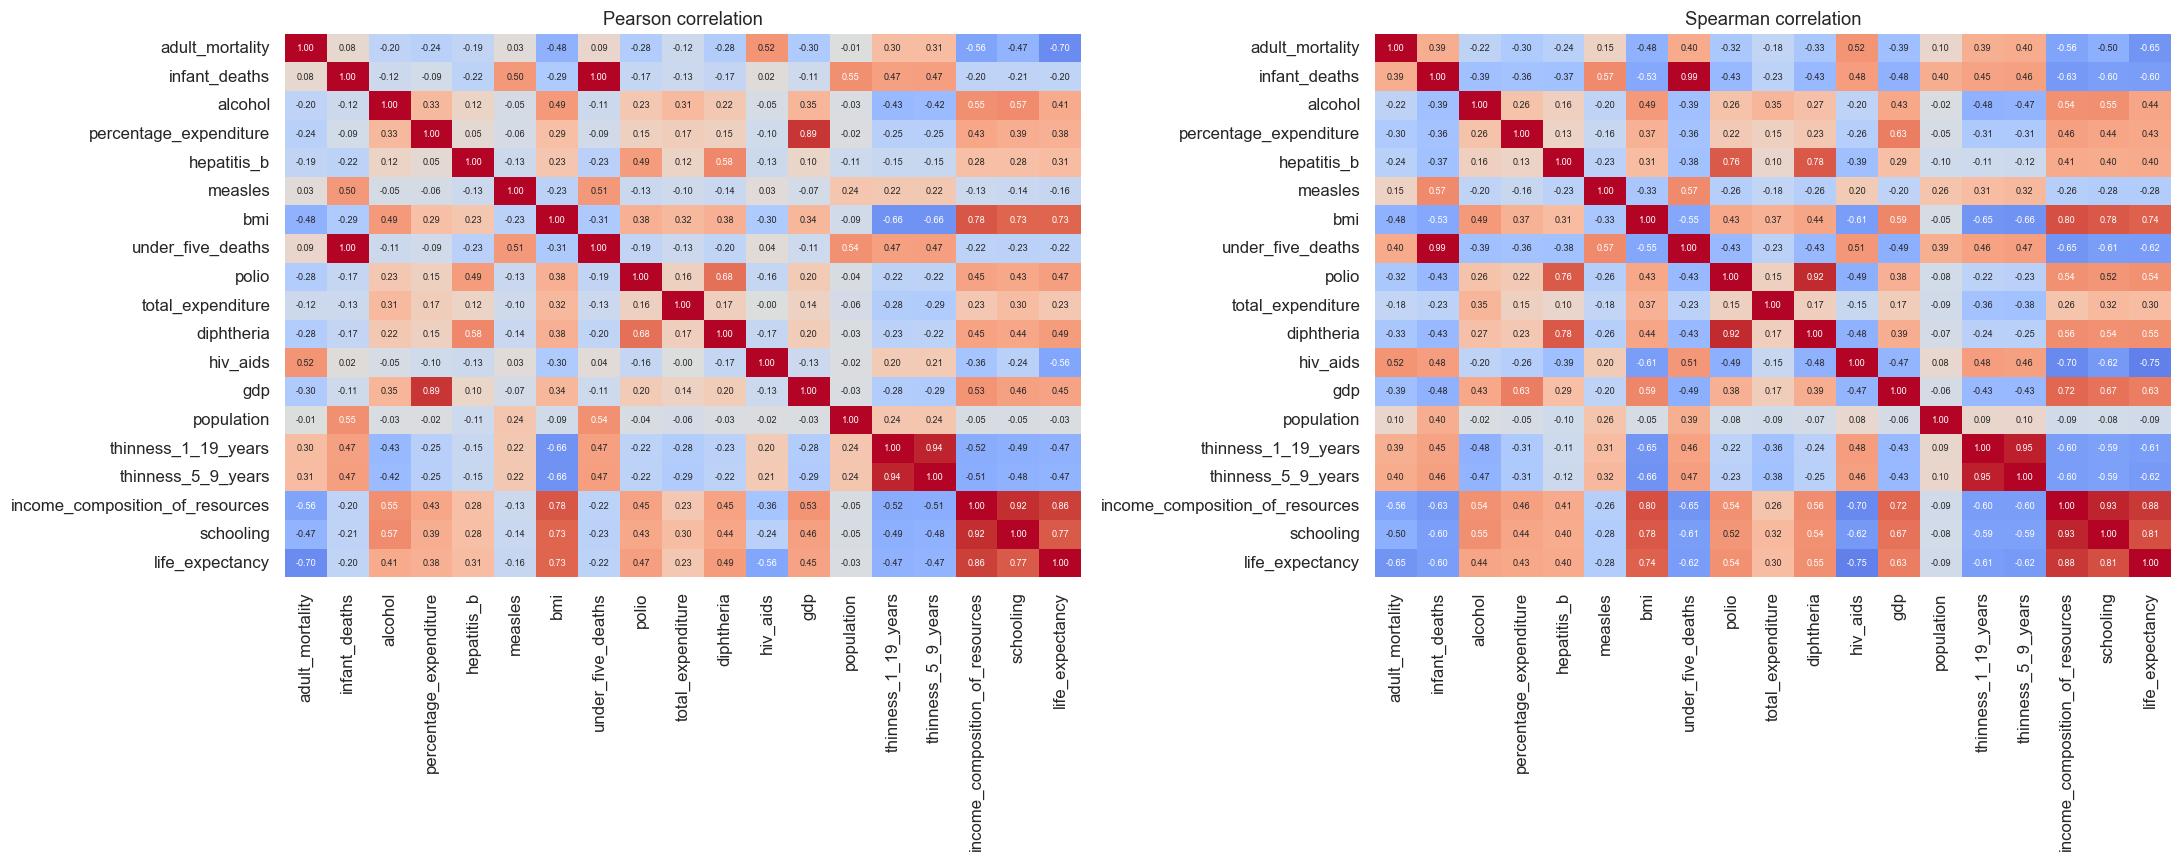

Predictor pairs with |r| > 0.7:


infant_deaths                    under_five_deaths                  0.997
thinness_1_19_years              thinness_5_9_years                 0.939
income_composition_of_resources  schooling                          0.919
percentage_expenditure           gdp                                0.893
bmi                              income_composition_of_resources    0.783
                                 schooling                          0.727
dtype: float64

Largest |Pearson - Spearman| gaps (non-linearity hint):


infant_deaths         0.402
under_five_deaths     0.394
hiv_aids              0.197
gdp                   0.182
thinness_5_9_years    0.153
dtype: float64

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 6}, ax=axes[0], cbar=False)
axes[0].set_title("Pearson correlation")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 6}, ax=axes[1], cbar=False)
axes[1].set_title("Spearman correlation")
save("correlation_heatmaps")

# Highly correlated predictor pairs (multicollinearity)
pairs = (corr_pearson.drop("life_expectancy").drop(columns="life_expectancy").abs().where(
    np.triu(np.ones((len(num_cols), len(num_cols))), k=1).astype(bool)).stack())
pairs = pairs[pairs > 0.7].sort_values(ascending=False).round(3)
pairs.to_csv("results/high_correlation_pairs.csv")
print("Predictor pairs with |r| > 0.7:"); display(pairs)

print("Largest |Pearson - Spearman| gaps (non-linearity hint):")
display((target_corr["spearman"] - target_corr["pearson"]).abs().sort_values(ascending=False).head(5).round(3))

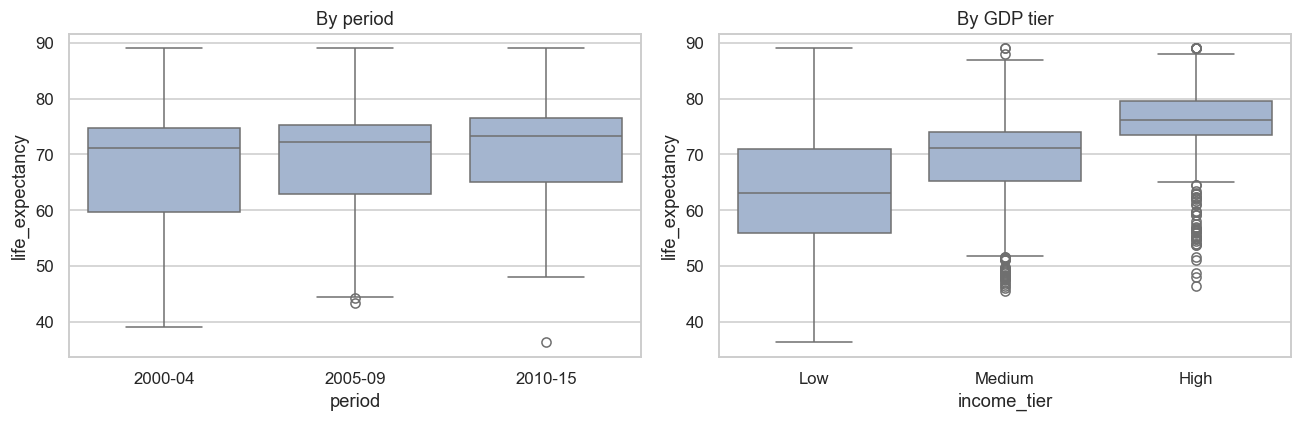

Welch t-test (Developed vs Developing): t = 47.87, p = 0
ANOVA life_expectancy ~ period: F = 39.70, p = 9.69e-18
ANOVA life_expectancy ~ income_tier: F = 691.15, p = 1.53e-246
Chi-square status vs income_tier: chi2 = 592.75, dof = 2, p = 1.93e-129

Hypothesis check (Pearson r with target):
H1 schooling: 0.765
H3 adult_mortality: -0.696


In [82]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=data, x="period", y="life_expectancy", color="#9DB4D6", ax=axes[0])
sns.boxplot(data=data, x="income_tier", y="life_expectancy", color="#9DB4D6", ax=axes[1])
axes[0].set_title("By period"); axes[1].set_title("By GDP tier")
save("categorical_vs_target")

# Statistical tests
dev = data.loc[data.status == "Developed", "life_expectancy"]
ing = data.loc[data.status == "Developing", "life_expectancy"]
t, p = stats.ttest_ind(dev, ing, equal_var=False)
print(f"Welch t-test (Developed vs Developing): t = {t:.2f}, p = {p:.3g}")

for cat in ["period", "income_tier"]:
    groups = [g["life_expectancy"].values for _, g in data.groupby(cat)]
    F, p = stats.f_oneway(*groups)
    print(f"ANOVA life_expectancy ~ {cat}: F = {F:.2f}, p = {p:.3g}")

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(data["status"], data["income_tier"]))
print(f"Chi-square status vs income_tier: chi2 = {chi2:.2f}, dof = {dof}, p = {p:.3g}")

print("\nHypothesis check (Pearson r with target):")
print("H1 schooling:", round(corr_pearson.loc["schooling", "life_expectancy"], 3))
print("H3 adult_mortality:", round(corr_pearson.loc["adult_mortality", "life_expectancy"], 3))

## 9. Model development

In [83]:
df_model = data.copy()

# 1) log1p on highly skewed features
for col in skew_cols:
    df_model[col] = np.log1p(df_model[col])

# 2) drop one feature from each near-duplicate pair (|r| > 0.9)
drop_collinear = ["under_five_deaths", "thinness_5_9_years"]

# 3) encode status (binary)
df_model["status"] = df_model["status"].map({"Developing": 0, "Developed": 1})

features = [c for c in num_cols if c not in drop_collinear] + ["year", "status"]
X, y, groups = df_model[features], df_model["life_expectancy"], df_model["country"]
print("Number of features:", len(features)); print(features)

Number of features: 18
['adult_mortality', 'infant_deaths', 'alcohol', 'percentage_expenditure', 'hepatitis_b', 'measles', 'bmi', 'polio', 'total_expenditure', 'diphtheria', 'hiv_aids', 'gdp', 'population', 'thinness_1_19_years', 'income_composition_of_resources', 'schooling', 'year', 'status']


In [84]:
# Split BY COUNTRY so the same country never appears in both train and test (avoids leakage across years)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

print(f"Train: {len(X_train)} rows ({g_train.nunique()} countries) | Test: {len(X_test)} rows ({groups.iloc[test_idx].nunique()} countries)")

# Scale AFTER splitting, fit on train only (status stays 0/1)
scale_cols = [c for c in features if c != "status"]
scaler = StandardScaler().fit(X_train[scale_cols])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[scale_cols] = scaler.transform(X_train[scale_cols])
X_test_s[scale_cols] = scaler.transform(X_test[scale_cols])

Train: 2336 rows (146 countries) | Test: 592 rows (37 countries)


In [85]:
# Multicollinearity check (VIF) on training features
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    Xc = X_train_s.assign(const=1.0)
    vif = pd.DataFrame({"feature": X_train_s.columns,
                        "VIF": [variance_inflation_factor(Xc.values, i) for i in range(len(X_train_s.columns))]})
    vif = vif.sort_values("VIF", ascending=False).round(2)
    vif.to_csv("results/vif.csv", index=False); display(vif)
except ImportError:
    print("statsmodels not installed -> skip VIF (pip install statsmodels)")

,feature,VIF
14,income_composition_of_resources,12.57
15,schooling,7.56
6,bmi,3.33
1,infant_deaths,3.04
11,gdp,2.82
9,diphtheria,2.43
10,hiv_aids,2.27
7,polio,2.22
13,thinness_1_19_years,2.02
2,alcohol,1.93


In [86]:
# Baseline: always predict the training mean
baseline_pred = np.full(len(y_test), y_train.mean())
baseline = {"model": "Baseline (mean)", "train_rmse": rmse(y_train, np.full(len(y_train), y_train.mean())),
            "cv_rmse": np.nan, "test_rmse": rmse(y_test, baseline_pred),
            "test_mae": mean_absolute_error(y_test, baseline_pred), "test_r2": r2_score(y_test, baseline_pred)}
print("Baseline test RMSE:", round(baseline["test_rmse"], 3))

cv = GroupKFold(n_splits=5)

# Ridge: tune alpha with grouped 5-fold CV
grid = GridSearchCV(Ridge(), {"alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
                    cv=cv, scoring="neg_root_mean_squared_error")
grid.fit(X_train_s, y_train, groups=g_train)
print("Best Ridge alpha:", grid.best_params_["alpha"], "| best CV RMSE:", round(-grid.best_score_, 4))
pd.DataFrame(grid.cv_results_)[["param_alpha", "mean_test_score", "std_test_score"]].assign(
    cv_rmse=lambda d: -d["mean_test_score"]).to_csv("results/ridge_tuning.csv", index=False)

Baseline test RMSE: 9.949


Best Ridge alpha: 10 | best CV RMSE: 3.6499


In [87]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (tuned)": grid.best_estimator_,
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

results, fitted = [baseline], {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    cv_rmse = -cross_val_score(model, X_train_s, y_train, cv=cv, groups=g_train,
                               scoring="neg_root_mean_squared_error").mean()
    pred_tr, pred_te = model.predict(X_train_s), model.predict(X_test_s)
    results.append({"model": name, "train_rmse": rmse(y_train, pred_tr), "cv_rmse": cv_rmse,
                    "test_rmse": rmse(y_test, pred_te), "test_mae": mean_absolute_error(y_test, pred_te),
                    "test_r2": r2_score(y_test, pred_te)})
    fitted[name] = model

results_df = pd.DataFrame(results).round(4)
results_df.to_csv("results/model_comparison.csv", index=False)
display(results_df)

,model,train_rmse,cv_rmse,test_rmse,test_mae,test_r2
0,Baseline (mean),9.4262,NaN,9.9487,7.9821,-0.0593
1,Linear Regression,3.3686,3.6538,3.2422,2.5075,0.8875
2,Ridge (tuned),3.3692,3.6499,3.2426,2.5029,0.8875
3,Random Forest,0.6373,2.9956,2.6476,1.9300,0.9250
4,Gradient Boosting,1.8457,3.0064,2.5890,1.9495,0.9283


## 10. Results and evaluation

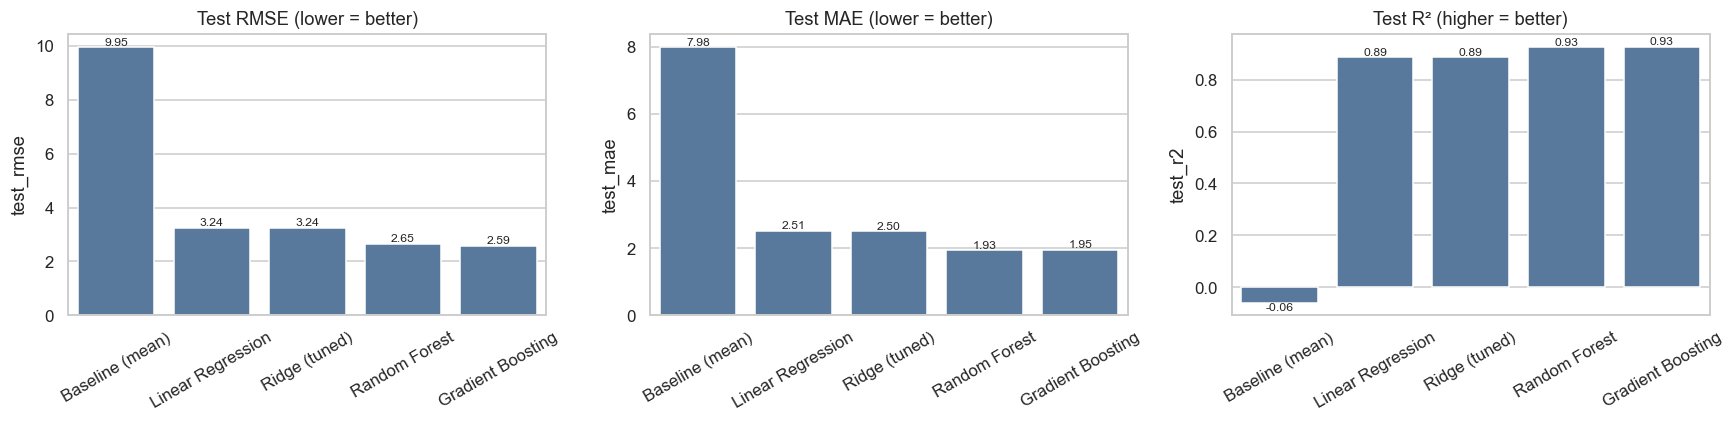

Best model by test RMSE: Gradient Boosting


In [88]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_df = results_df.copy()
for ax, metric, title in zip(axes, ["test_rmse", "test_mae", "test_r2"], ["Test RMSE (lower = better)", "Test MAE (lower = better)", "Test R² (higher = better)"]):
    sns.barplot(data=plot_df, x="model", y=metric, color="#4C78A8", ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
save("model_comparison")

best_name = results_df[results_df["model"] != "Baseline (mean)"].sort_values("test_rmse").iloc[0]["model"]
best_model = fitted[best_name]
print("Best model by test RMSE:", best_name)

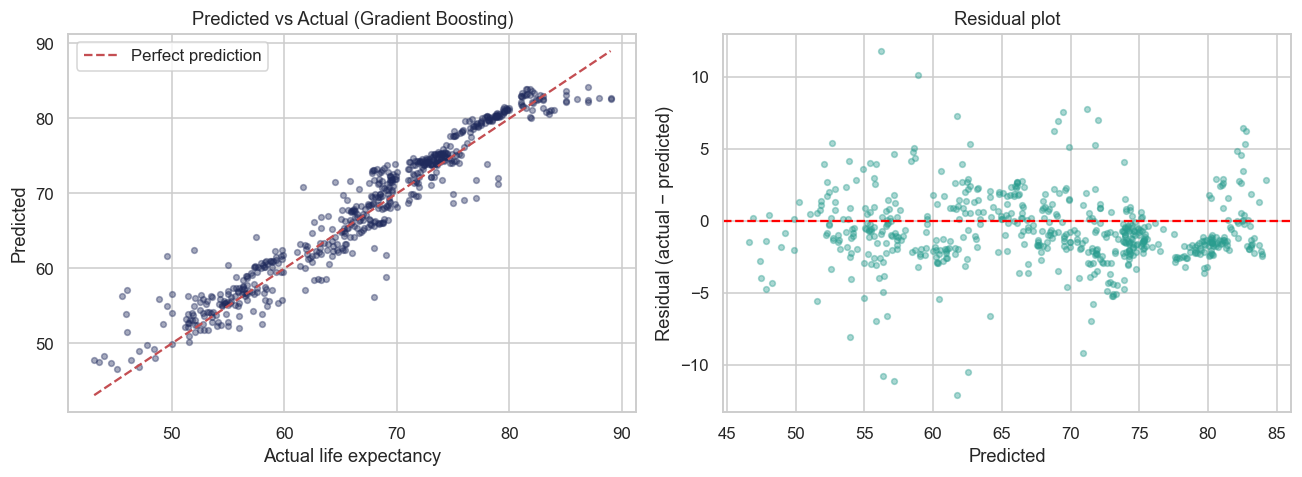

Residual mean: -0.708 | residual std: 2.492


In [89]:
pred = best_model.predict(X_test_s)
resid = y_test - pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred, alpha=0.4, s=14, color="#1F2A5C")
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual life expectancy"); axes[0].set_ylabel("Predicted"); axes[0].legend()
axes[0].set_title(f"Predicted vs Actual ({best_name})")
axes[1].scatter(pred, resid, alpha=0.4, s=14, color="#2A9D8F")
axes[1].axhline(0, color="red", ls="--"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Residual plot")
save("pred_vs_actual_residuals")
print("Residual mean:", round(resid.mean(), 3), "| residual std:", round(resid.std(), 3))

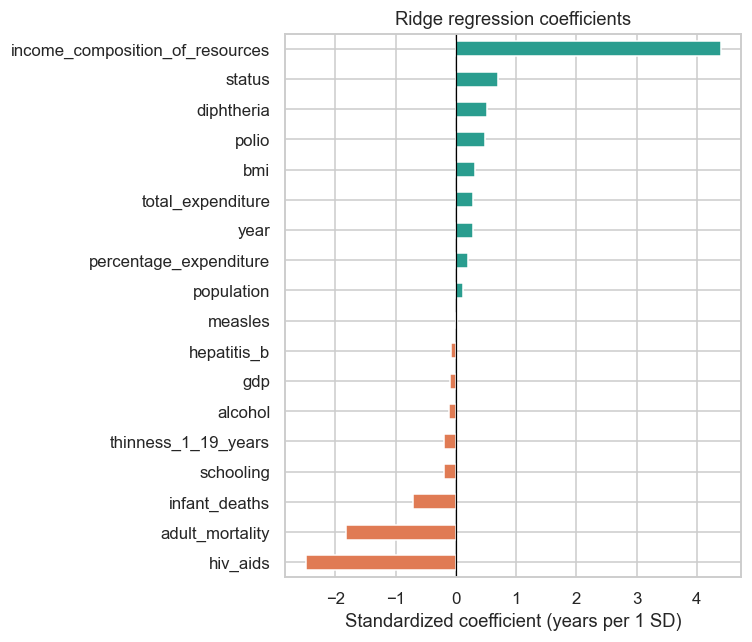

,coefficient
income_composition_of_resources,4.396
status,0.706
diphtheria,0.520
polio,0.487
bmi,0.317
total_expenditure,0.286
year,0.285
percentage_expenditure,0.200
population,0.119
measles,0.021


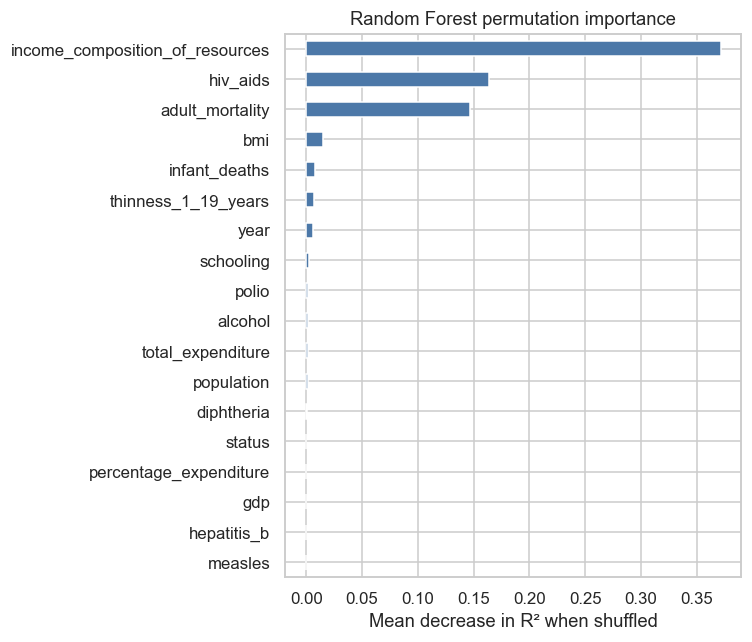

In [90]:
# Ridge standardized coefficients (direction + size of each effect)
coef = pd.Series(fitted["Ridge (tuned)"].coef_, index=X_train_s.columns).sort_values()
coef.round(3).to_csv("results/ridge_coefficients.csv", header=["coefficient"])
plt.figure(figsize=(7, 6))
coef.plot(kind="barh", color=["#E07B54" if v < 0 else "#2A9D8F" for v in coef])
plt.axvline(0, color="black", lw=0.8); plt.xlabel("Standardized coefficient (years per 1 SD)")
plt.title("Ridge regression coefficients")
save("ridge_coefficients")
display(coef.sort_values(ascending=False).round(3).to_frame("coefficient"))

# Random Forest permutation importance on the test set
pi = permutation_importance(fitted["Random Forest"], X_test_s, y_test, n_repeats=10,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test_s.columns).sort_values()
imp.round(4).to_csv("results/rf_permutation_importance.csv", header=["importance"])
plt.figure(figsize=(7, 6)); imp.plot(kind="barh", color="#4C78A8")
plt.xlabel("Mean decrease in R² when shuffled"); plt.title("Random Forest permutation importance")
save("rf_permutation_importance")

## 11. Summary for the report

In [91]:
best_row = results_df[results_df["model"] == best_name].iloc[0]
print("=" * 60)
print("RAW SHAPE:", raw_shape, "| CLEANED SHAPE:", data.shape)
print("COUNTRIES:", data["country"].nunique(), "| YEARS:", data["year"].min(), "-", data["year"].max())
print("COLUMNS WITH MISSING (raw):", len(miss_table))
print("TARGET: mean", round(data["life_expectancy"].mean(), 2), "std", round(data["life_expectancy"].std(), 2),
      "min", data["life_expectancy"].min(), "max", data["life_expectancy"].max())
print("FEATURES USED:", len(features), "| dropped (collinear):", drop_collinear, "| log1p on:", skew_cols)
print("TRAIN/TEST:", len(X_train), "/", len(X_test))
print("BASELINE TEST RMSE:", round(baseline["test_rmse"], 3))
print("BEST MODEL:", best_name, "| test RMSE", best_row["test_rmse"], "| MAE", best_row["test_mae"], "| R2", best_row["test_r2"])
print("TOP 3 POSITIVE COEFS:", coef.sort_values(ascending=False).head(3).round(3).to_dict())
print("TOP 3 NEGATIVE COEFS:", coef.sort_values().head(3).round(3).to_dict())
print("=" * 60)

import shutil
shutil.make_archive("report_outputs", "zip", ".", "figs")
shutil.make_archive("report_results", "zip", ".", "results")
try:
    from google.colab import files
    files.download("report_outputs.zip"); files.download("report_results.zip")
except ImportError:
    print("Figures: figs/  |  Tables: results/  (also zipped)")

RAW SHAPE: (2938, 22) | CLEANED SHAPE: (2928, 24)
COUNTRIES: 183 | YEARS: 2000 - 2015
COLUMNS WITH MISSING (raw): 14
TARGET: mean 69.22 std 9.52 min 36.3 max 89.0
FEATURES USED: 18 | dropped (collinear): ['under_five_deaths', 'thinness_5_9_years'] | log1p on: ['infant_deaths', 'percentage_expenditure', 'measles', 'under_five_deaths', 'hiv_aids', 'gdp', 'population', 'thinness_1_19_years', 'thinness_5_9_years']
TRAIN/TEST: 2336 / 592
BASELINE TEST RMSE: 9.949
BEST MODEL: Gradient Boosting | test RMSE 2.589 | MAE 1.9495 | R2 0.9283
TOP 3 POSITIVE COEFS: {'income_composition_of_resources': 4.396, 'status': 0.706, 'diphtheria': 0.52}
TOP 3 NEGATIVE COEFS: {'hiv_aids': -2.494, 'adult_mortality': -1.815, 'infant_deaths': -0.714}


Figures: figs/  |  Tables: results/  (also zipped)
